In [265]:
# ============================================================
# Example
# ============================================================

In [266]:
import numpy as np
import matplotlib.pyplot as plt 
import sys

sys.path.append(r"C:\Users\barar\Documents\GitHub\AnalyticalSolvers")

import FM_inPlaneSWMs as sswms

In [267]:
# --------------------------------------------------------
# Material parameters: example YIG-like values
# --------------------------------------------------------

mu0 = 4*3.14e-7
material = "Co"

if (material == "Fe"):

    Ms = 2.15/mu0       # A/m

    A = 19.4e-12          # J/m
    d = 20e-9             # m

    Ku = -45e3            # J/m^3
    K1 = 2.3e-3           # J/m^3

if (material == "Co"):

    Ms = 1.410e6      # A/m

    A = 28.5e-12          # J/m
    d = 35e-9            # m

    Ku = 0.0            # J/m^3
    #K1 = 4.5e5           # J/m^3
    K1 = 0.0

# --------------------------------------------------------
# Applied field
# --------------------------------------------------------

B = np.array([
    0.0,  # Bx (T)
    0.0,  # By (T)
    0.1,  # Bz (T)
])



(<Figure size 700x450 with 1 Axes>,
 <Axes: title={'center': 'Thickness-mode dispersion versus field'}, xlabel='Applied field (mT)', ylabel='Frequency (GHz)'>)

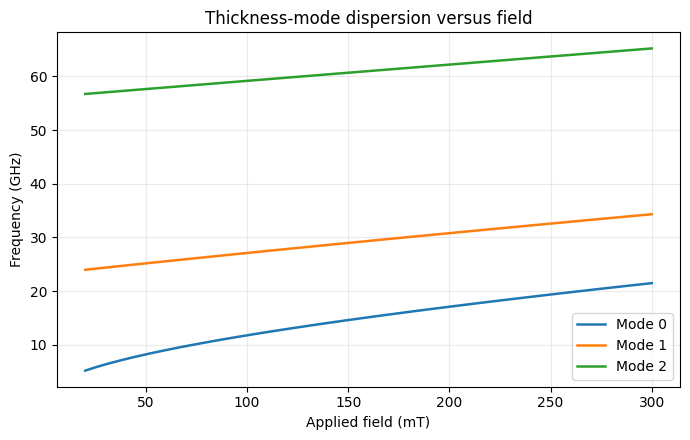

In [268]:
# --------------------------------------------------------
# f(H) sweep
# --------------------------------------------------------

fields = np.linspace(0.02, 0.3, 50)
k = 3.9e6  # rad/m

frequencies_H, vectors_H, results_H = sswms.sweep_field(
    fields=fields,
    field_direction=[1, 0, 0],
    kx=k,
    ky=0.0,
    Ms=Ms,
    A=A,
    d=d,
    Ku=Ku,
    K1=K1,
    n_modes=3,
)

sswms.plot_frequency_sweep(
    fields * 1e3,
    frequencies_H,
    xlabel="Applied field (mT)",
    title="Thickness-mode dispersion versus field",
)

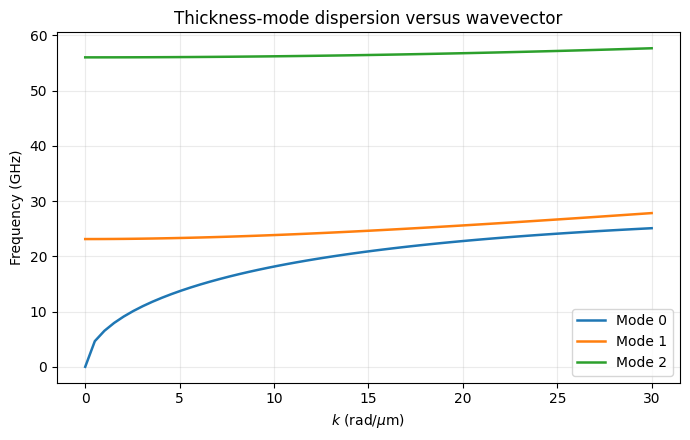

In [269]:
# --------------------------------------------------------
# f(k) sweep
# --------------------------------------------------------

k_values = np.linspace(0, 30e6, 60)

frequencies_k, vectors_k, results_k = sswms.sweep_wavevector(
    k_values=k_values,
    propagation_angle=0.0,
    B=B,
    Ms=Ms,
    A=A,
    d=d,
    Ku=Ku,
    K1=K1,
    n_modes=3,
)

sswms.plot_frequency_sweep(
    k_values * 1e-6,
    frequencies_k,
    xlabel=r"$k$ ($\mathrm{rad}/\mu\mathrm{m}$)",
    title="Thickness-mode dispersion versus wavevector",
)

plt.show()



Eigenfrequencies:
Mode 0: 12.27748 GHz
Mode 1: 23.25246 GHz
Mode 2: 56.06741 GHz

Equilibrium magnetization:
[ 0.012656   -0.99832589  0.05643792]


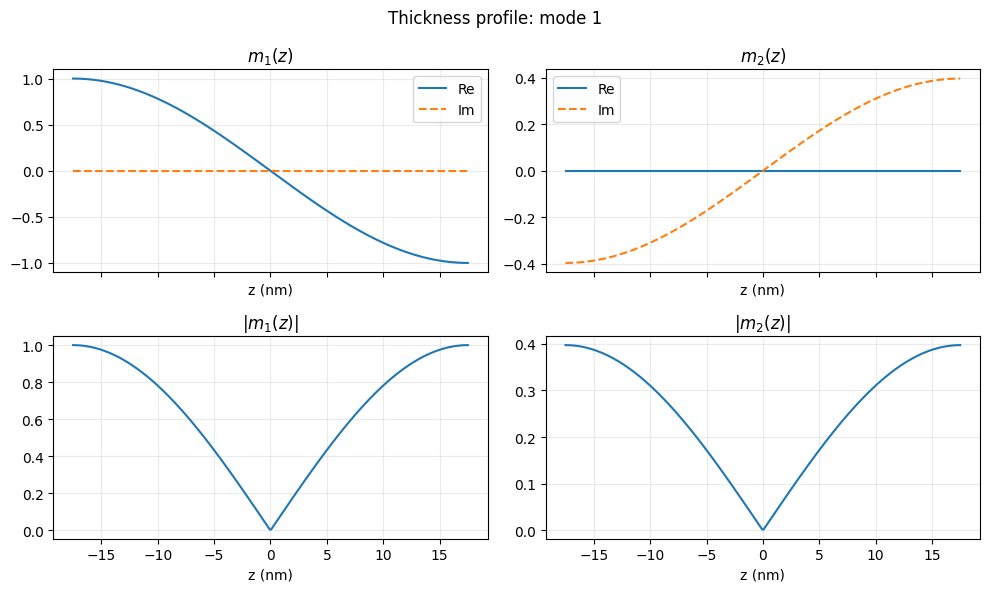

In [270]:
# --------------------------------------------------------
# Single-point calculation
# --------------------------------------------------------

k = 3.9e6  # rad/m

result = sswms.solve_modes(
    kx=k,
    ky=0.0,
    B=B,
    Ms=Ms,
    A=A,
    d=d,
    Ku=Ku,
    K1=K1,
    n_modes=3,
    n_quad=100,
)

print("\nEigenfrequencies:")
for n, f in enumerate(result["frequency"]):
    print(f"Mode {n}: {f/1e9:.5f} GHz")

print("\nEquilibrium magnetization:")
print(result["equilibrium"])

sswms.plot_mode_profile(result, mode_index=1)
plt.show()

In [271]:
# --------------------------------------------------------
# Analytical Kittel validation
# --------------------------------------------------------

#sswms.validate_kittel_limit()
